# Estimating k: how fast fills drop off with distance

The Avellaneda–Stoikov (A–S) market maker rests a back and a lay on each runner, a distance $\delta$ away from the mid price. Quoting further away gets a better price when we're filled, but we're filled less often. A–S assumes the **fill rate** falls off exponentially with distance:

$$\lambda(\delta) = A\,e^{-k\delta}$$

- $\lambda(\delta)$ is the expected number of fills per second for a quote at distance $\delta$ from the mid.
- $A$ is the fill rate right at the mid. It only scales how often we trade and drops out of the A–S quote formulas, so we don't need it.
- $k$ is how quickly fills fall away as we quote further out. **This is what we estimate.**

$k$ sets the fill term of the A–S half-spread, $\frac1\gamma\ln\!\left(1+\frac\gamma k\right)$. A large $k$ means fills disappear quickly as we step back from the mid, so it pays to quote tight. A small $k$ means we can quote wider without losing many fills.

We estimate a separate $k$ for **back** quotes and **lay** quotes in each time bin before the off. We use January 2025 only and measure every distance in **log-odds**. σ² lives in `volatility.ipynb`, and this notebook uses the same conventions.

**The plan**

1. Every 5 seconds from 350 s to 35 s before the off, take each runner's mid price.
2. Place pretend quotes at every ladder price near the mid and see which would have been filled over the next 5 seconds, using the backtest engine's rules, queue included.
3. In each time bin, work out how often a quote at distance δ = 0.01, 0.02, …, 0.30 would have been filled, and turn that into a fill rate λ(δ).
4. Fit a straight line to ln λ against δ. The slope is −k.
5. Merge any bin that can't be fitted, add 95% confidence intervals, check the estimate day by day, and compare it with the market's spread.
6. Print `K_BACK_X` and `K_LAY_X` to paste into `strategies/_final-strategy.py`.

## Distances in log-odds

As in the σ² notebook, a runner whose best back odds are $B$ and best lay odds are $L$ has mid price

$$S = \tfrac12\left(\frac1B + \frac1L\right), \qquad x_0 = \ln\frac{S}{1-S}$$

A single price, like a trade at odds $O$, has probability $1/O$, which in log-odds is

$$x = \ln\frac{1/O}{1-1/O} = -\ln(O-1)$$

Higher $x$ means shorter odds (more likely to win). Our two quotes sit either side of the mid:

| Our quote | Where it sits | It's filled when |
|---|---|---|
| **Back** (we back at longer odds than the mid) | below the mid, at $x_0-\delta$ | someone lays at that price |
| **Lay** (we lay at shorter odds than the mid) | above the mid, at $x_0+\delta$ | someone backs at that price |

For scale: one tick on Betfair's price ladder is between about 0.01 and 0.05 in log-odds for runners priced 1.2 to 6.0, so steps of 0.01 in δ are never coarser than a tick.

The strategy converts $k$ to probability units with $k_p = k_x / [S(1-S)]$ (in `ASGMStrategy._as_prices`).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from matplotlib.lines import Line2D

# Project root = the folder that holds data/ (works whether this runs from research/ or the root)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "processed").exists())
sys.path.insert(0, str(ROOT))
from strategies.asmodel import LADDER   # Betfair's price ladder (1.01, 1.02, ..., 1000), to count ticks

FILES = sorted((ROOT / "data/processed/market_stream/Jan").glob("*/*/*.parquet"))   # one file per race

GRID = np.arange(350, 34, -5)       # window start times in seconds before the off: 350, 345, ..., 35
LATENCY = 0.2                       # seconds before an order we send is in the market
WINDOW = 5                          # seconds our order is live in each window
DELTAS = np.round(np.arange(0.01, 0.305, 0.01), 2)   # quote distances from the mid (log-odds): 0.01, ..., 0.30
SIDES = {"back": "down", "lay": "up"}                # which distance fills which quote (see Step 1)
MIN_ODDS, MAX_ODDS = 1.2, 6.0       # only runners the strategy would quote
P_RANGE = (0.02, 0.98)              # only fit distances whose fill probability is inside this range
MIN_K = 2                           # a bin with k below this, or that can't be fitted, is merged with a neighbour
BIN_EDGES = [30, 45, 60, 90, 120, 180, 240, 300, 350]   # time bins, seconds before the off (same as σ²)
BINS = BIN_EDGES[1:]                # each bin is named by its upper edge
N_BOOT = 1000                       # bootstrap repeats
rng = np.random.default_rng(42)     # fixed seed so the confidence intervals are reproducible

LADDER = np.array(LADDER)
LEVELS = [1, 2, 3]                  # the data keeps the best three prices on each side
LADDER_COLUMNS = [f"{side}_{what}_{i}" for side in ("back", "lay") for what in ("price", "size") for i in LEVELS]

# Chart style: blue = back quotes, orange = lay quotes, greys for everything else, a light hairline grid
COLOURS = {"back": "#2a78d6", "lay": "#eb6834"}
GREY = "#898781"                    # secondary marks
LIGHT = "#c3c2b7"                   # background detail: the moving mid, single days, axis lines
INK, INK_2 = "#0b0b0b", "#52514e"   # headlines; labels and tick numbers
%config InlineBackend.figure_format = "retina"
plt.rcParams.update({
    "figure.figsize": (8, 4.2), "figure.facecolor": "white", "axes.facecolor": "white",
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "Helvetica Neue", "Arial", "DejaVu Sans"],
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK_2, "axes.labelpad": 6,
    "xtick.color": LIGHT, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2, "ytick.major.size": 0,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": LIGHT, "axes.linewidth": 0.8,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "lines.markersize": 7, "lines.markeredgewidth": 1.5, "lines.markeredgecolor": "white",
    "legend.frameon": False, "legend.fontsize": 9.5,
})


def titles(ax, title, subtitle):
    # A bold headline that states the finding, then a smaller line saying what is plotted. Both are kept out of
    # the layout, so in a figure with several panels they can run across all of them.
    note = ax.annotate(subtitle, (0, 1), xycoords="axes fraction", xytext=(0, 10), textcoords="offset points",
                       fontsize=9.5, color=INK_2, va="bottom", linespacing=1.45)
    head = ax.set_title(title, loc="left", fontsize=12.5, fontweight="semibold",
                        pad=16 + 14 * (subtitle.count("\n") + 1))
    note.set_in_layout(False)
    head.set_in_layout(False)


def legend(ax, **kwargs):
    # A legend whose keys drop the white ring around markers (on a short key it makes a line look dashed)
    for key in ax.legend(**kwargs).legend_handles:
        if isinstance(key, Line2D):
            key.set_markeredgewidth(0)


print(f"{len(FILES):,} January WIN markets")

4,072 January WIN markets


## Step 1: A 5-second window every 5 seconds

For each runner we start a window at 350, 345, …, 35 seconds before the off and ask: *if we had placed a quote at the start, how far from the mid could it have been and still been filled?*

**Mid at the start**, $x_0$: from the latest book update at or before the start (the same rule as for σ²).

**Pretend quotes.** At the start we send a back at every ladder price with longer odds than the mid, and a lay at every ladder price with shorter odds, out to 0.30 in log-odds (the furthest distance we fit). Betfair only accepts prices on its ladder, so these are all the quotes we could have placed. Each reaches the market 0.2 s later (latency) and stays until the window ends, 5.2 s after the start.

**Which would have been filled.** We use the backtest engine's own rules (`backtest/execution.py`), so $k$ describes the fills the backtest will actually give the strategy:

| Fill | What happens |
|---|---|
| Crossed | The other side of the book moves onto our price, so we're matched with the money offered there. |
| Traded through | Someone trades at a price that's worse for them than ours. Betfair matches the best price first, so they'd have taken ours. |
| Queue used up | Money already waiting at our price is ahead of us. Trades at our price use it up, and once it's gone, the rest comes to us. |

The queue matters most near the off. A quote inside the spread is the best price on offer, so nobody is ahead of it. A quote that joins the best price, or sits behind it, has to wait its turn: the money ahead of it is what's visible at its price when it arrives. If that visible amount later drops below what we think is ahead of us, people ahead must have cancelled, so we move up. Beyond the three visible prices we can't see the queue, so it counts as infinite until the price comes into view. Traded amounts are halved, because Betfair counts each matched bet twice.

**How far out a fill reached.** A quote further from the mid can only be filled if the nearer ones are too: anything that crosses it, trades through it or trades at its price also reaches every quote in front of it. So one number per side sums up each window, the distance from the mid of the furthest quote that was filled:

$$\text{down} = \text{furthest back filled}, \qquad \text{up} = \text{furthest lay filled}$$

A back at distance δ is filled if **down ≥ δ**, and a lay if **up ≥ δ**. A quote "at distance δ" means the first ladder price at least δ from the mid, the way the strategy rounds its quotes away from the mid. If nothing is filled, the window counts as "no fill" at every distance.

**Which windows count.** We keep a window only if:

- the market is `OPEN` at the start;
- the mid odds at the start are between 1.2 and 6.0 (this also drops runners missing a back or lay price);
- the market is still open at the end: the end (start + 5.2 s) isn't after the market's last open update;
- the market isn't suspended at any point while our order is live (for example, for a late scratching).

The last two rules stop a closed market from looking like a quiet one: nobody can trade while it's shut, so those windows would wrongly count as "no fill". The first catches markets that close for good before the window ends, and the second catches suspensions part-way through it.

**Runners near 1.2 and 6.0.** The odds filter only looks at the start of the window, because that's when the strategy decides whether to quote. A runner that drifts from 5.9 to 6.3 during the window still counts, and its trades are exactly the ones that would have hit our back. A runner that hovers around 6.0 contributes only the windows that start inside the range.

In [2]:
def load_book(path):
    # Every book update in one race (one row per runner per update, in time order for each runner),
    # with time to the off and the mid
    book = pd.read_parquet(path, columns=["publish_time", "market_time", "status", "selection_id",
                                          *LADDER_COLUMNS, "traded_prices", "traded_sizes"])
    # A market that never had a price (one abandoned race) stores empty price columns, so force numbers
    book = book.astype({column: float for column in LADDER_COLUMNS})
    off = book["market_time"].iloc[-1]                                # scheduled off (its final value)
    book["ttj"] = (off - book["publish_time"]).dt.total_seconds()     # seconds before the off
    book["publish_time"] = book["publish_time"].dt.as_unit("ns")      # merge_asof needs one time unit
    S = 0.5 * (1 / book["back_price_1"] + 1 / book["lay_price_1"])    # mid, as a probability
    book["odds"] = 1 / S
    book["x"] = np.log(S / (1 - S))                                   # mid, in log-odds
    return book.sort_values(["selection_id", "publish_time"], kind="stable").reset_index(drop=True)


def trade_list(book):
    # One row per trade: the runner, seconds before the off, and the traded price in log-odds
    trades = book.loc[book["traded_prices"].map(len) > 0, ["selection_id", "ttj", "traded_prices"]]
    trades = trades.explode("traded_prices")          # one update can show trades at several prices
    trades["x"] = -np.log(trades["traded_prices"].astype(float) - 1)
    return trades


# Window t is live from t - 0.2 to t - 5.2 seconds before the off. The windows are 5 s long and start 5 s apart,
# so they sit end to end: window t covers times to the off in [t - 5.2, t - 0.2), and pd.cut can find
# the window any moment belongs to.
STARTS = GRID[::-1]                                                                  # 35, 40, ..., 350
EDGES = np.round(np.append(STARTS - LATENCY - WINDOW, STARTS[-1] - LATENCY), 1)     # 29.8, 34.8, ..., 349.8


def window_of(ttj):
    # The window whose live period contains each time (missing if it's in none of them)
    return pd.cut(ttj, EDGES, right=False, labels=STARTS).astype("Int64")


def find_update(book, runners, times, direction):
    # The row of each runner's update at or after ("forward") or at or before ("backward") each time
    wanted = pd.DataFrame({"selection_id": runners, "time": times}).reset_index(drop=True)
    wanted["order"] = np.arange(len(wanted))
    updates = book[["selection_id", "publish_time"]].reset_index(names="row")
    found = pd.merge_asof(wanted.sort_values("time"), updates.sort_values("publish_time", kind="stable"),
                          left_on="time", right_on="publish_time", by="selection_id", direction=direction)
    return found.sort_values("order")["row"].to_numpy()


def runs(first, count):
    # first, first + 1, ..., first + count - 1 for each pair, all joined together
    return np.repeat(first, count) + np.arange(count.sum()) - np.repeat(np.cumsum(count) - count, count)


def pretend_quotes(book, windows, off):
    # A back at every ladder price with longer odds than the mid and a lay at every price with shorter odds,
    # out to the first price at least DELTAS[-1] away. Sent at the window's start, each is live from the first
    # update after it arrives (0.2 s later) to the last update before the window ends (5.2 s after the start).
    start = (off - pd.to_timedelta(windows["t"], unit="s")).dt.as_unit("ns")
    windows = windows.assign(
        arrival_row=find_update(book, windows["selection_id"], start + pd.Timedelta(seconds=LATENCY), "forward"),
        end_row=find_update(book, windows["selection_id"], start + pd.Timedelta(seconds=LATENCY + WINDOW), "backward"))
    windows = windows[windows["arrival_row"] <= windows["end_row"]]     # no update while live: can't be filled
    quotes = []
    for side in SIDES:
        sign = -1 if side == "back" else 1
        furthest = 1 + np.exp(-(windows["x0"].to_numpy() + sign * DELTAS[-1]))   # odds DELTAS[-1] from the mid
        if side == "back":
            first = np.searchsorted(LADDER, windows["odds"].to_numpy() + 1e-9)
            last = np.minimum(np.searchsorted(LADDER, furthest - 1e-9), len(LADDER) - 1)
        else:
            first = np.maximum(np.searchsorted(LADDER, furthest + 1e-9, side="right") - 1, 0)
            last = np.searchsorted(LADDER, windows["odds"].to_numpy() - 1e-9) - 1
        count = np.clip(last - first + 1, 0, None)
        quote = windows.iloc[np.repeat(np.arange(len(windows)), count)][["selection_id", "t", "x0", "arrival_row", "end_row"]]
        quote = quote.reset_index(drop=True).assign(side=side, price=LADDER[runs(first, count)])
        quote["distance"] = (quote["x0"] + np.log(quote["price"] - 1)).abs()   # from the mid, in log-odds
        quotes.append(quote)
    return pd.concat(quotes, ignore_index=True).astype({"arrival_row": int, "end_row": int})


def visible_queue(life, side):
    # Money waiting at each quote's price on its own side of the book (the engine's _visible_queue)
    own = "lay" if side == "back" else "back"     # a resting back waits among the money available to lay
    in_front = (lambda ours, level: ours < level) if side == "back" else (lambda ours, level: ours > level)
    queue = pd.Series(np.nan, index=life.index)
    depth = pd.Series(0, index=life.index)        # how many price levels the book shows
    for i in LEVELS:
        level, size = life[f"{own}_price_{i}"], life[f"{own}_size_{i}"]
        shown = level.notna() & (depth == i - 1)
        depth += shown
        open_question = queue.isna() & shown
        same_price = open_question & ((level - life["price"]).abs() < 1e-6)
        queue[same_price] = size[same_price]
        queue[open_question & ~same_price & in_front(life["price"], level)] = 0.0
    beyond = queue.isna()
    queue[beyond] = np.where(depth[beyond] == len(LEVELS), np.inf, 0.0)   # unseen if the book is full
    return queue


def filled(book, quotes):
    # Whether each quote gets at least part of a fill under the engine's three rules
    length = (quotes["end_row"] - quotes["arrival_row"] + 1).to_numpy()
    life = pd.DataFrame({"quote": np.repeat(np.arange(len(quotes)), length),
                         "row": runs(quotes["arrival_row"].to_numpy(), length)})
    life["arrival"] = life["row"] == np.repeat(quotes["arrival_row"].to_numpy(), length)
    life = life.join(quotes[["side", "price"]], on="quote").join(book[["status", *LADDER_COLUMNS]], on="row")
    life = life[(life["status"] == "OPEN").groupby(life["quote"]).cummin()].copy()   # a suspension ends the quote

    # Crossed: money on the other side of the book at our price or better
    back = life["side"] == "back"
    life["crossing"] = False
    for i in LEVELS:
        life["crossing"] |= np.where(back, life[f"back_price_{i}"] >= life["price"] - 1e-9,
                                     life[f"lay_price_{i}"] <= life["price"] + 1e-9)

    # Trades at our price, and through it, after our quote arrives (halved: Betfair counts each bet twice)
    trades = book.loc[book["traded_prices"].map(len) > 0, ["traded_prices", "traded_sizes"]]
    trades = trades.explode(["traded_prices", "traded_sizes"]).astype(float).rename_axis("row").reset_index()
    trades = life.loc[~life["arrival"], ["quote", "row", "side", "price"]].merge(trades, on="row")
    at_price = (trades["traded_prices"] - trades["price"]).abs() < 1e-6
    worse = np.where(trades["side"] == "back", trades["traded_prices"] > trades["price"],
                     trades["traded_prices"] < trades["price"])
    trades["at_price"] = np.where(at_price, trades["traded_sizes"] / 2, 0.0)
    trades["through"] = np.where(~at_price & worse, trades["traded_sizes"] / 2, 0.0)
    life = life.join(trades.groupby(["quote", "row"])[["at_price", "through"]].sum(), on=["quote", "row"])
    life[["at_price", "through"]] = life[["at_price", "through"]].fillna(0.0)

    # Queue used up: with C the amount traded at our price so far, z = queue + C is a running minimum
    life["visible"] = np.nan
    life.loc[back, "visible"] = visible_queue(life[back], "back")
    life.loc[~back, "visible"] = visible_queue(life[~back], "lay")
    C = life.groupby("quote")["at_price"].cumsum()
    z = (life["visible"] + C).groupby(life["quote"]).cummin()

    hit = life["crossing"] | (life["through"] > 0) | (C > z + 1e-9)
    return hit.groupby(life["quote"]).any().reindex(range(len(quotes)), fill_value=False).to_numpy()


def windows_in_race(path):
    # One row per runner per window: the mid at the start, the distance of the furthest back (down) and lay (up)
    # that would have been filled, and whether the window passes each rule
    book = load_book(path)
    off = book["market_time"].iloc[-1]

    # The mid at each window's start: the latest book update at or before it
    starts = pd.MultiIndex.from_product([book["selection_id"].unique(), GRID],
                                        names=["selection_id", "t"]).to_frame(index=False)
    starts["time"] = (off - pd.to_timedelta(starts["t"], unit="s")).dt.as_unit("ns")
    snap = pd.merge_asof(starts.sort_values("time"), book.sort_values("publish_time", kind="stable"),
                         left_on="time", right_on="publish_time", by="selection_id", direction="backward")
    windows = pd.DataFrame({
        "race": path.stem,                      # market id
        "day": int(path.parent.parent.name),    # files live in Jan/<day>/<event>/<market>.parquet
        "selection_id": snap["selection_id"],
        "t": snap["t"],                         # window start, seconds before the off
        "odds": snap["odds"],
        "x0": snap["x"],
    })

    # The rules from the text above
    last_open = book.loc[book["status"] == "OPEN", "ttj"].min()                  # the market's last OPEN update
    suspended = window_of(book.loc[book["status"] != "OPEN", "ttj"]).dropna()    # windows with a suspension
    windows["open"] = snap["status"] == "OPEN"
    windows["in_range"] = windows["odds"].between(MIN_ODDS, MAX_ODDS)            # a missing price fails too
    windows["open_at_end"] = windows["t"] - LATENCY - WINDOW >= last_open
    windows["never_suspended"] = ~windows["t"].isin(suspended)

    # Pretend quotes where the strategy could quote, and the furthest one filled on each side
    quotes = pretend_quotes(book, windows[windows["open"] & windows["in_range"]], off)
    reach = quotes[filled(book, quotes)].groupby(["selection_id", "t", "side"])["distance"].max()
    reach = reach.unstack("side").reindex(columns=list(SIDES)).rename(columns={"back": "down", "lay": "up"})
    return windows.join(reach, on=["selection_id", "t"])


all_windows = pd.concat(Parallel(n_jobs=-1)(delayed(windows_in_race)(f) for f in FILES), ignore_index=True)

# Apply the rules one at a time, to see how many windows each one removes
RULES = {
    "open": "market not open at the start",
    "in_range": "mid odds not between 1.2 and 6.0 at the start",
    "open_at_end": "market closed before the window ended",
    "never_suspended": "market suspended while our order was live",
}
keep = pd.Series(True, index=all_windows.index)
print(f"{len(all_windows):>9,} windows (every runner, every 5 s from 350 s to 35 s before the off)")
for column, reason in RULES.items():
    print(f"{(keep & ~all_windows[column]).sum():>9,} removed: {reason}")
    keep &= all_windows[column]
windows = all_windows[keep].reset_index(drop=True)
print(f"{len(windows):>9,} windows kept, from {windows['race'].nunique():,} races")

1,897,664 windows (every runner, every 5 s from 350 s to 35 s before the off)
   56,627 removed: market not open at the start
1,299,321 removed: mid odds not between 1.2 and 6.0 at the start
       51 removed: market closed before the window ended
       20 removed: market suspended while our order was live
  541,645 windows kept, from 3,957 races


In [3]:
print(f"{windows['down'].notna().mean():.0%} of windows would have filled a back somewhere, "
      f"{windows['up'].notna().mean():.0%} a lay")
print(f"A back 0.01 below the mid would have been filled in {(windows['down'] >= 0.01).mean():.0%} of windows, "
      f"a lay 0.01 above it in {(windows['up'] >= 0.01).mean():.0%}")
windows[["race", "selection_id", "t", "odds", "x0", "down", "up"]].head()

24% of windows would have filled a back somewhere, 24% a lay
A back 0.01 below the mid would have been filled in 16% of windows, a lay 0.01 above it in 21%


,race,selection_id,t,odds,x0,down,up
0,1.237721878,78433718,350,2.266432,-0.236203,NaN,NaN
1,1.237721878,77928213,350,4.272832,-1.185656,NaN,NaN
2,1.237721878,78433718,345,2.266432,-0.236203,NaN,0.087783
3,1.237721878,77928213,345,4.272832,-1.185656,NaN,NaN
4,1.237721878,77928213,340,4.303448,-1.194967,NaN,NaN


Here is one window up close: the first race's favourite, in the first window where both a back and a lay would have been filled. The dark line is the mid at the start, the light grey line is the mid as it moved, and the black dots are trades. The shaded strip is the latency, when our order isn't in the market yet, so trades there don't count. The arrows show how far out the furthest filled back and lay sat. They stop short of the furthest trades: money was already waiting at those prices, and the trades there didn't use it all up, so a quote joining them wouldn't have been reached. The quotes just in front were traded through.

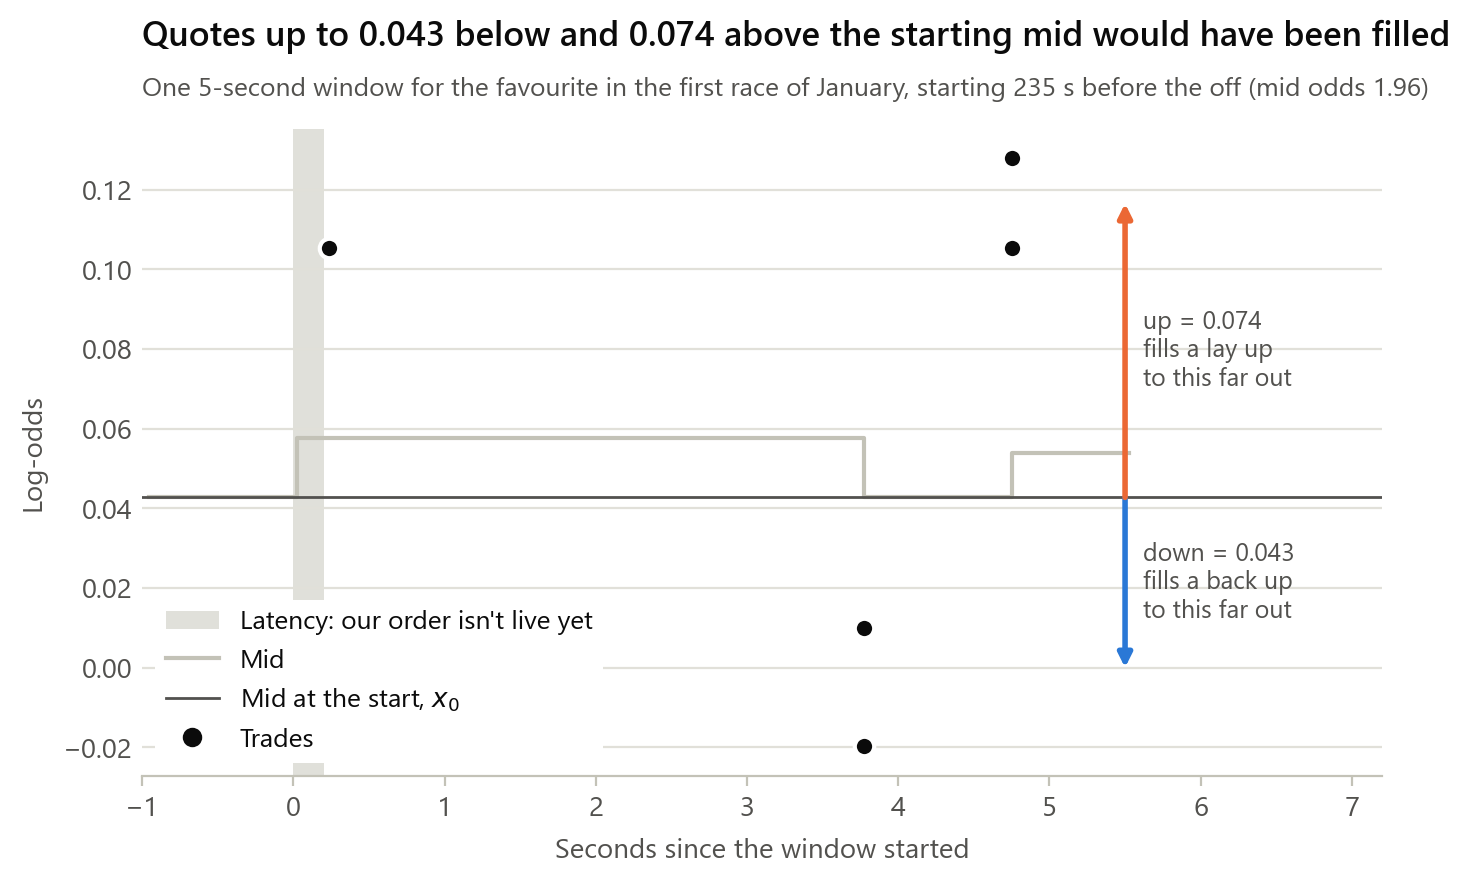

In [4]:
race = FILES[0]
in_race = windows[windows["race"] == race.stem]
favourite = in_race.loc[in_race["t"] == in_race["t"].max()].sort_values("odds")["selection_id"].iloc[0]  # shortest odds
w = in_race[(in_race["selection_id"] == favourite) & (in_race["down"] > 0) & (in_race["up"] > 0)].iloc[0]

book = load_book(race)
book = book[book["selection_id"] == favourite]
trades = trade_list(book)
since_start = w["t"] - book["ttj"]                     # seconds since the window started
trade_secs = w["t"] - trades["ttj"]
live = (trade_secs > LATENCY) & (trade_secs <= LATENCY + WINDOW)

fig, ax = plt.subplots()
ax.axvspan(0, LATENCY, color=LIGHT, alpha=0.5, lw=0, label="Latency: our order isn't live yet")
shown = since_start.between(-1, LATENCY + WINDOW + 0.5)
ax.step(since_start[shown], book["x"][shown], where="post", color=LIGHT, lw=1.5, label="Mid")
ax.axhline(w["x0"], color=INK_2, lw=1, label="Mid at the start, $x_0$")
ax.plot(trade_secs[live], trades["x"][live], "o", color=INK, label="Trades")

# Arrows from the starting mid to the lowest and highest trades
end = LATENCY + WINDOW + 0.3
for side, sign in [("back", -1), ("lay", 1)]:
    distance = w[SIDES[side]]
    ax.annotate("", xy=(end, w["x0"] + sign * distance), xytext=(end, w["x0"]),
                arrowprops=dict(arrowstyle="-|>", color=COLOURS[side], lw=2, shrinkA=0, shrinkB=0))
    ax.text(end + 0.12, w["x0"] + sign * distance / 2, f"{SIDES[side]} = {distance:.3f}\nfills a {side} up\nto this far out",
            va="center", fontsize=9, color=INK_2)
ax.set(xlim=(-1, end + 1.7), xlabel="Seconds since the window started", ylabel="Log-odds")
legend(ax, loc="lower left", frameon=True, facecolor="white", edgecolor="none", framealpha=1)
titles(ax, f"Quotes up to {w['down']:.3f} below and {w['up']:.3f} above the starting mid would have been filled",
       f"One 5-second window for the favourite in the first race of January, starting {w['t']} s before the off "
       f"(mid odds {w['odds']:.2f})")
plt.show()

## Step 2: Fill probability and fill rate

Each window goes in the time bin of its **start**. Bins are written as (lower, upper], e.g. (30, 45], and named by their upper edge, exactly as in the σ² notebook. That matches the strategy's tables, where each bin is named by its upper edge, and it gives the window starting at 350 s a bin. Writing them as [lower, upper) instead would only change which bin a window starting exactly on an edge (45, 60, 90, …) belongs to.

In one bin and on one side, say there are $n$ windows and a quote at distance δ would have been filled in $h(\delta)$ of them. The **fill probability** is

$$P(\delta) = \frac{h(\delta)}{n}$$

the chance that a quote at δ is filled within 5 seconds.

A–S needs a **rate** (fills per second), not a probability. It assumes fills arrive at random at a steady rate λ (a Poisson process), so the chance of at least one fill in 5 seconds is $P = 1 - e^{-5\lambda}$. Solving for λ:

$$\lambda(\delta) = -\frac{\ln\big(1-P(\delta)\big)}{5}$$

For small $P$ this is about $P/5$: P = 0.05 gives λ = 0.0103 per second. For larger P it's bigger than P/5, because a window only tells us whether there was *at least one* fill, and could hide several: P = 0.6 gives λ = 0.18, not 0.12.

**Totals by race.** As with σ², everything we need can be built from totals per race. For each race and bin we count the windows, and, for each δ, how many of them would have filled a back (and a lay). Every estimate is then a **weighted sum over races**:

- the **pooled** estimate gives every race a weight of 1. This is our main estimate of $k$ (Steps 3 and 4, and the Results);
- a **bootstrap** sample weights each race by how many times it was drawn. A thousand of these give the 95% confidence intervals (Step 5) and the back-against-lay test;
- a **daily** estimate gives that day's races a weight of 1 and the rest 0. One per day gives the day-to-day check (Step 6).

In the code, the weights are one number per race, and `totals(weights, side)` does the weighted sum, so all three estimates share the same fitting code.

In [5]:
windows["bin"] = pd.cut(windows["t"], BIN_EDGES, labels=BINS).astype(int)   # (30, 45] -> 45, ..., (300, 350] -> 350
LABELS = {hi: f"({lo}, {hi}]" for lo, hi in zip(BIN_EDGES[:-1], BIN_EDGES[1:])}
RACES = windows["race"].unique()


def race_totals(values):
    # Add up `values` (one row per window) within each race and bin -> array indexed [race, bin, column]
    totals = values.groupby([windows["race"], windows["bin"]]).sum()
    every_cell = pd.MultiIndex.from_product([RACES, BINS])     # include bins where a race has no windows
    return totals.reindex(every_cell, fill_value=0).to_numpy().reshape(len(RACES), len(BINS), -1)


# window_counts[race, bin] = number of windows
window_counts = race_totals(pd.DataFrame({"windows": 1}, index=windows.index))[:, :, 0]

# fill_counts[side][race, bin, j] = windows in which that side's quote at distance DELTAS[j] would have been filled.
# A window with no trades has down = up = NaN, and NaN >= δ is False, so it counts as no fill.
fill_counts = {side: race_totals(pd.DataFrame({d: windows[column] >= d for d in DELTAS}))
               for side, column in SIDES.items()}


def totals(weights, side):
    # Weighted sum over races: windows per bin, and fills per bin and distance
    return weights @ window_counts, np.tensordot(weights, fill_counts[side], axes=1)


EVERY_RACE = np.ones(len(RACES))     # weights for the pooled estimate
pd.Series(window_counts.sum(axis=0), index=[LABELS[b] for b in BINS], name="windows").rename_axis("seconds before off")

seconds before off
(30, 45]       25996
(45, 60]       26019
(60, 90]       52084
(90, 120]      52059
(120, 180]    104127
(180, 240]    102299
(240, 300]     99077
(300, 350]     79984
Name: windows, dtype: int64

Here is the fill probability against distance for four of the bins. Close to the off, a quote near the mid is far more likely to be filled: about 40% of windows in the last 45 seconds at δ = 0.01, against about 5% at 300–350 s. But that chance falls away much faster with distance, and by δ ≈ 0.08 the four bins are about level. A steeper fall is exactly what a larger $k$ means.

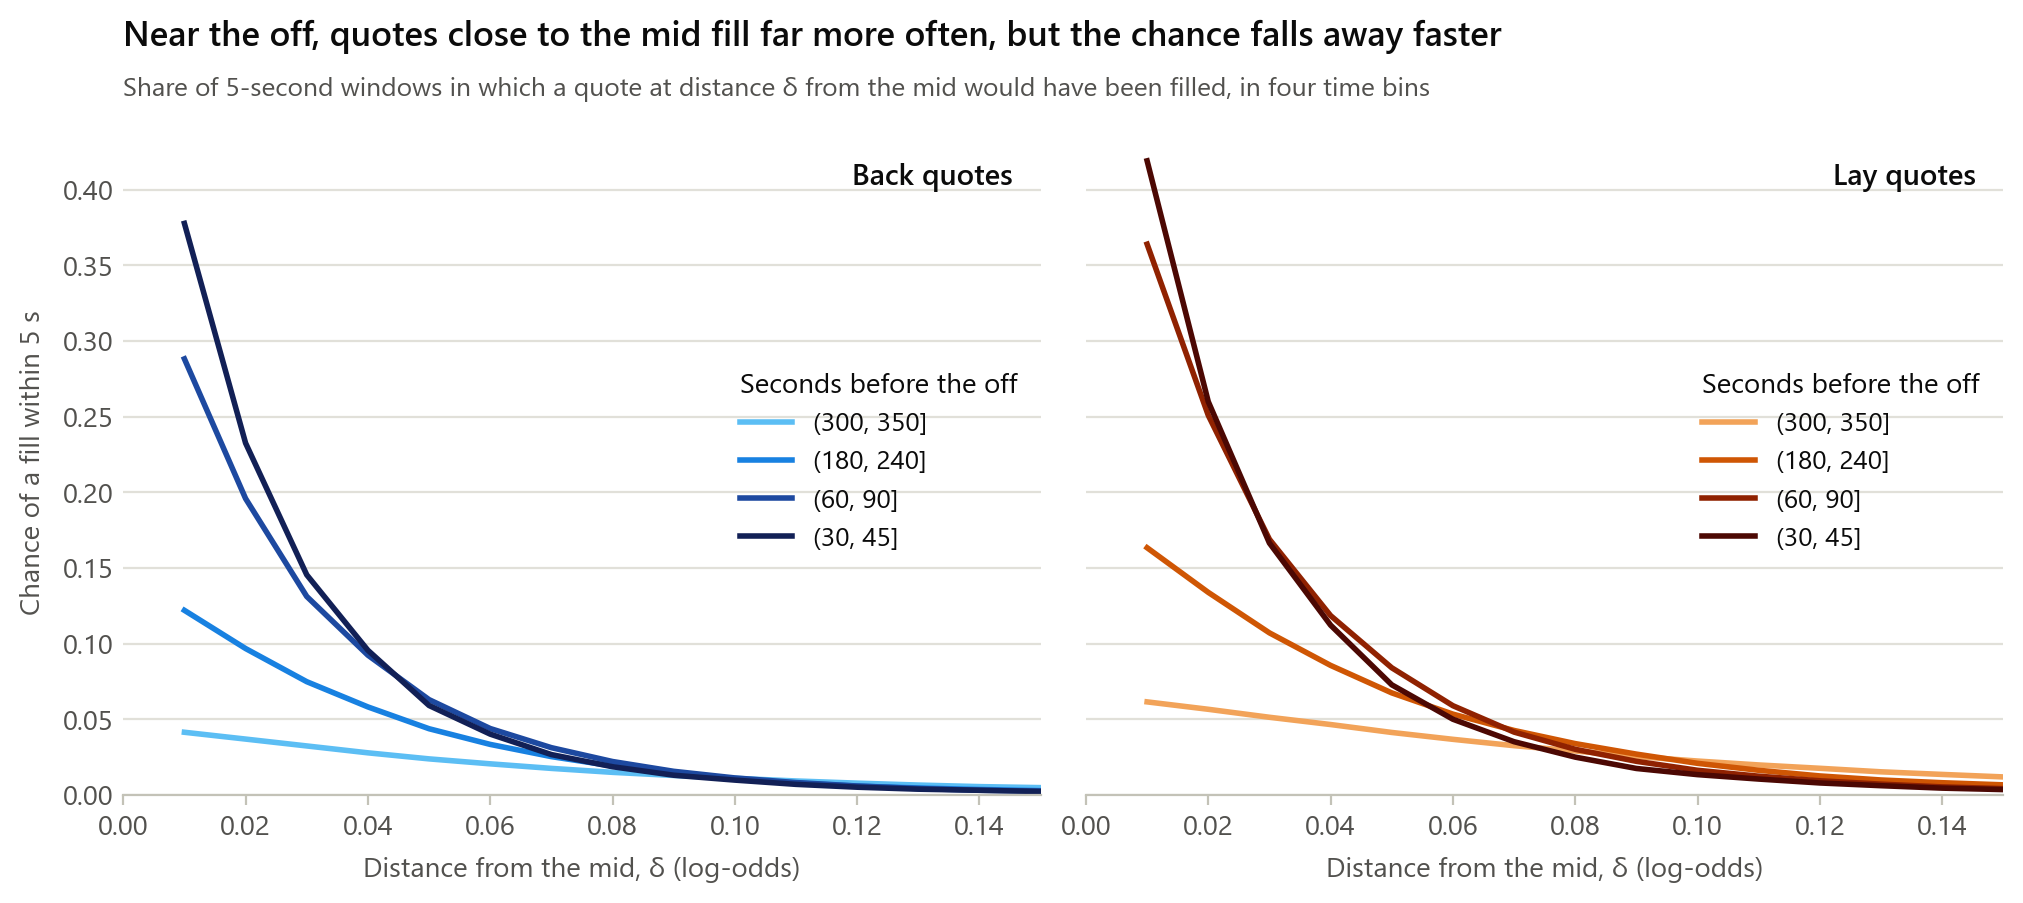

In [6]:
SHOWN = [350, 240, 90, 45]                              # far from the off ... close to it
RAMPS = {"back": ["#5cbef4", "#1881e1", "#1d49a0", "#122056"],   # each side's colour, light = far from the off,
         "lay": ["#f2a359", "#cf5604", "#902201", "#4c0803"]}    # dark = close to it

fig, axes = plt.subplots(1, 2, sharey=True, figsize=(10, 4.4), layout="constrained")
for ax, side in zip(axes, SIDES):
    n_tot, h_tot = totals(EVERY_RACE, side)
    for b, colour in zip(SHOWN, RAMPS[side]):
        i = BINS.index(b)
        ax.plot(DELTAS, h_tot[i] / n_tot[i], color=colour, label=f"{LABELS[b]}")
    ax.text(0.97, 0.95, f"{side.title()} quotes", transform=ax.transAxes, ha="right", va="top",
            fontsize=10.5, fontweight="semibold")
    ax.set(xlabel="Distance from the mid, δ (log-odds)", xlim=(0, 0.15))
    legend(ax, title="Seconds before the off", loc="center right", alignment="left")
axes[0].set(ylabel="Chance of a fill within 5 s", ylim=(0, None))   # after both panels, so neither is cut off
titles(axes[0], "Near the off, quotes close to the mid fill far more often, but the chance falls away faster",
       "Share of 5-second windows in which a quote at distance δ from the mid would have been filled, in four time bins")
plt.show()

## Step 3: Fit a straight line to find k

Taking logs of $\lambda(\delta) = A\,e^{-k\delta}$ gives a straight line:

$$\ln\lambda(\delta) = \ln A - k\,\delta$$

So in each bin we plot ln λ against δ, fit a line by ordinary least squares, and read off $k = -\text{slope}$.

We only use the distances where $0.02 < P(\delta) < 0.98$:

- Below 2%, the probability rests on very few fills, so its log is noisy (and with no fills at all, it's $-\infty$).
- Above 98%, $-\ln(1-P)$ blows up, so tiny changes in P make huge changes in λ.

A bin needs at least 3 usable distances, otherwise it can't be fitted. In practice P never gets near 98%, so the 2% floor decides how far out we fit.

In [7]:
def fill_rates(n, h, p_range=P_RANGE):
    # Fill probability and fill rate at each distance, and which distances the fit may use
    P = h / n if n > 0 else np.zeros(len(DELTAS))
    rate = -np.log(1 - P) / WINDOW
    usable = (P > p_range[0]) & (P < p_range[1])
    return P, rate, usable


def fit_k(n, h, p_range=P_RANGE):
    # k for one bin, from n windows and h[j] = windows filled at distance DELTAS[j] (NaN if it can't be fitted)
    P, rate, usable = fill_rates(n, h, p_range)
    if usable.sum() < 3:
        return np.nan
    slope, intercept = np.polyfit(DELTAS[usable], np.log(rate[usable]), 1)
    return -slope


def k_by_group(weights, side, groups, p_range=P_RANGE):
    # k for each group of bins (a group is a list of bin positions), from a weighted sum of race totals
    n_tot, h_tot = totals(weights, side)
    return np.array([fit_k(n_tot[g].sum(), h_tot[g].sum(axis=0), p_range) for g in groups])


ONE_BIN_EACH = [[i] for i in range(len(BINS))]
k_per_bin = {side: k_by_group(EVERY_RACE, side, ONE_BIN_EACH) for side in SIDES}
pd.DataFrame(k_per_bin, index=[LABELS[b] for b in BINS]).rename_axis("seconds before off").round(1)

,back,lay
seconds before off,,
"(30, 45]",47.4,43.3
"(45, 60]",38.1,40.3
"(60, 90]",38.7,37.4
"(90, 120]",36.6,36.7
"(120, 180]",32.9,30.5
"(180, 240]",27.2,23.8
"(240, 300]",20.0,17.1
"(300, 350]",14.4,11.6


Each panel below is one bin. Filled dots are the distances used in the fit, and hollow dots are the distances left out because fewer than 2% of windows reached them. **A straight line through the filled dots means A–S's exponential assumption holds.**

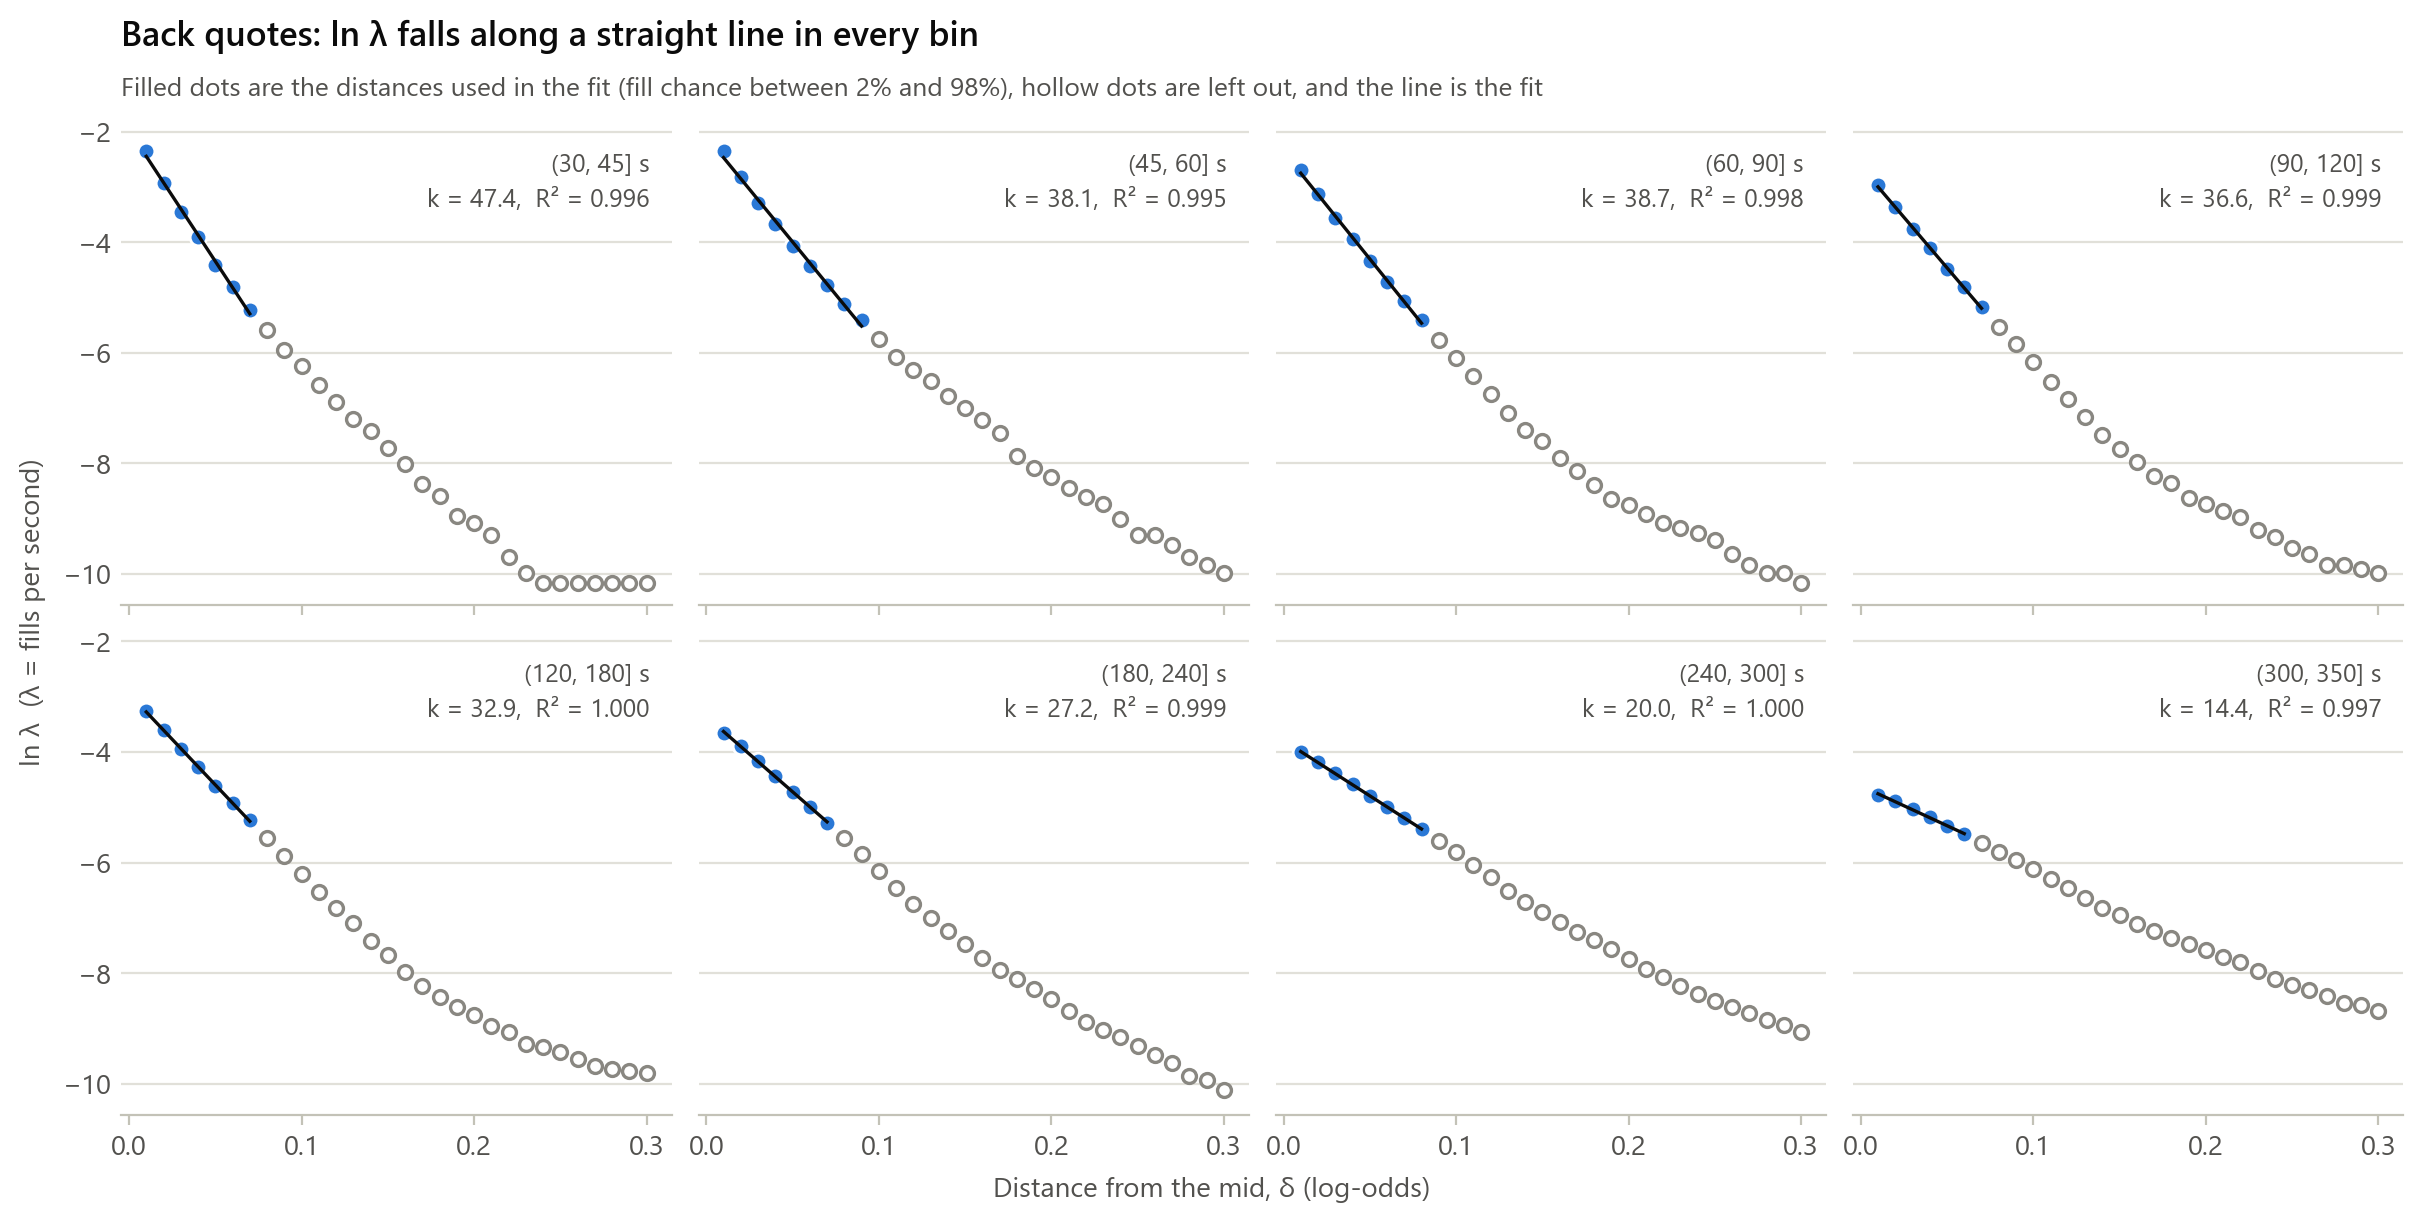

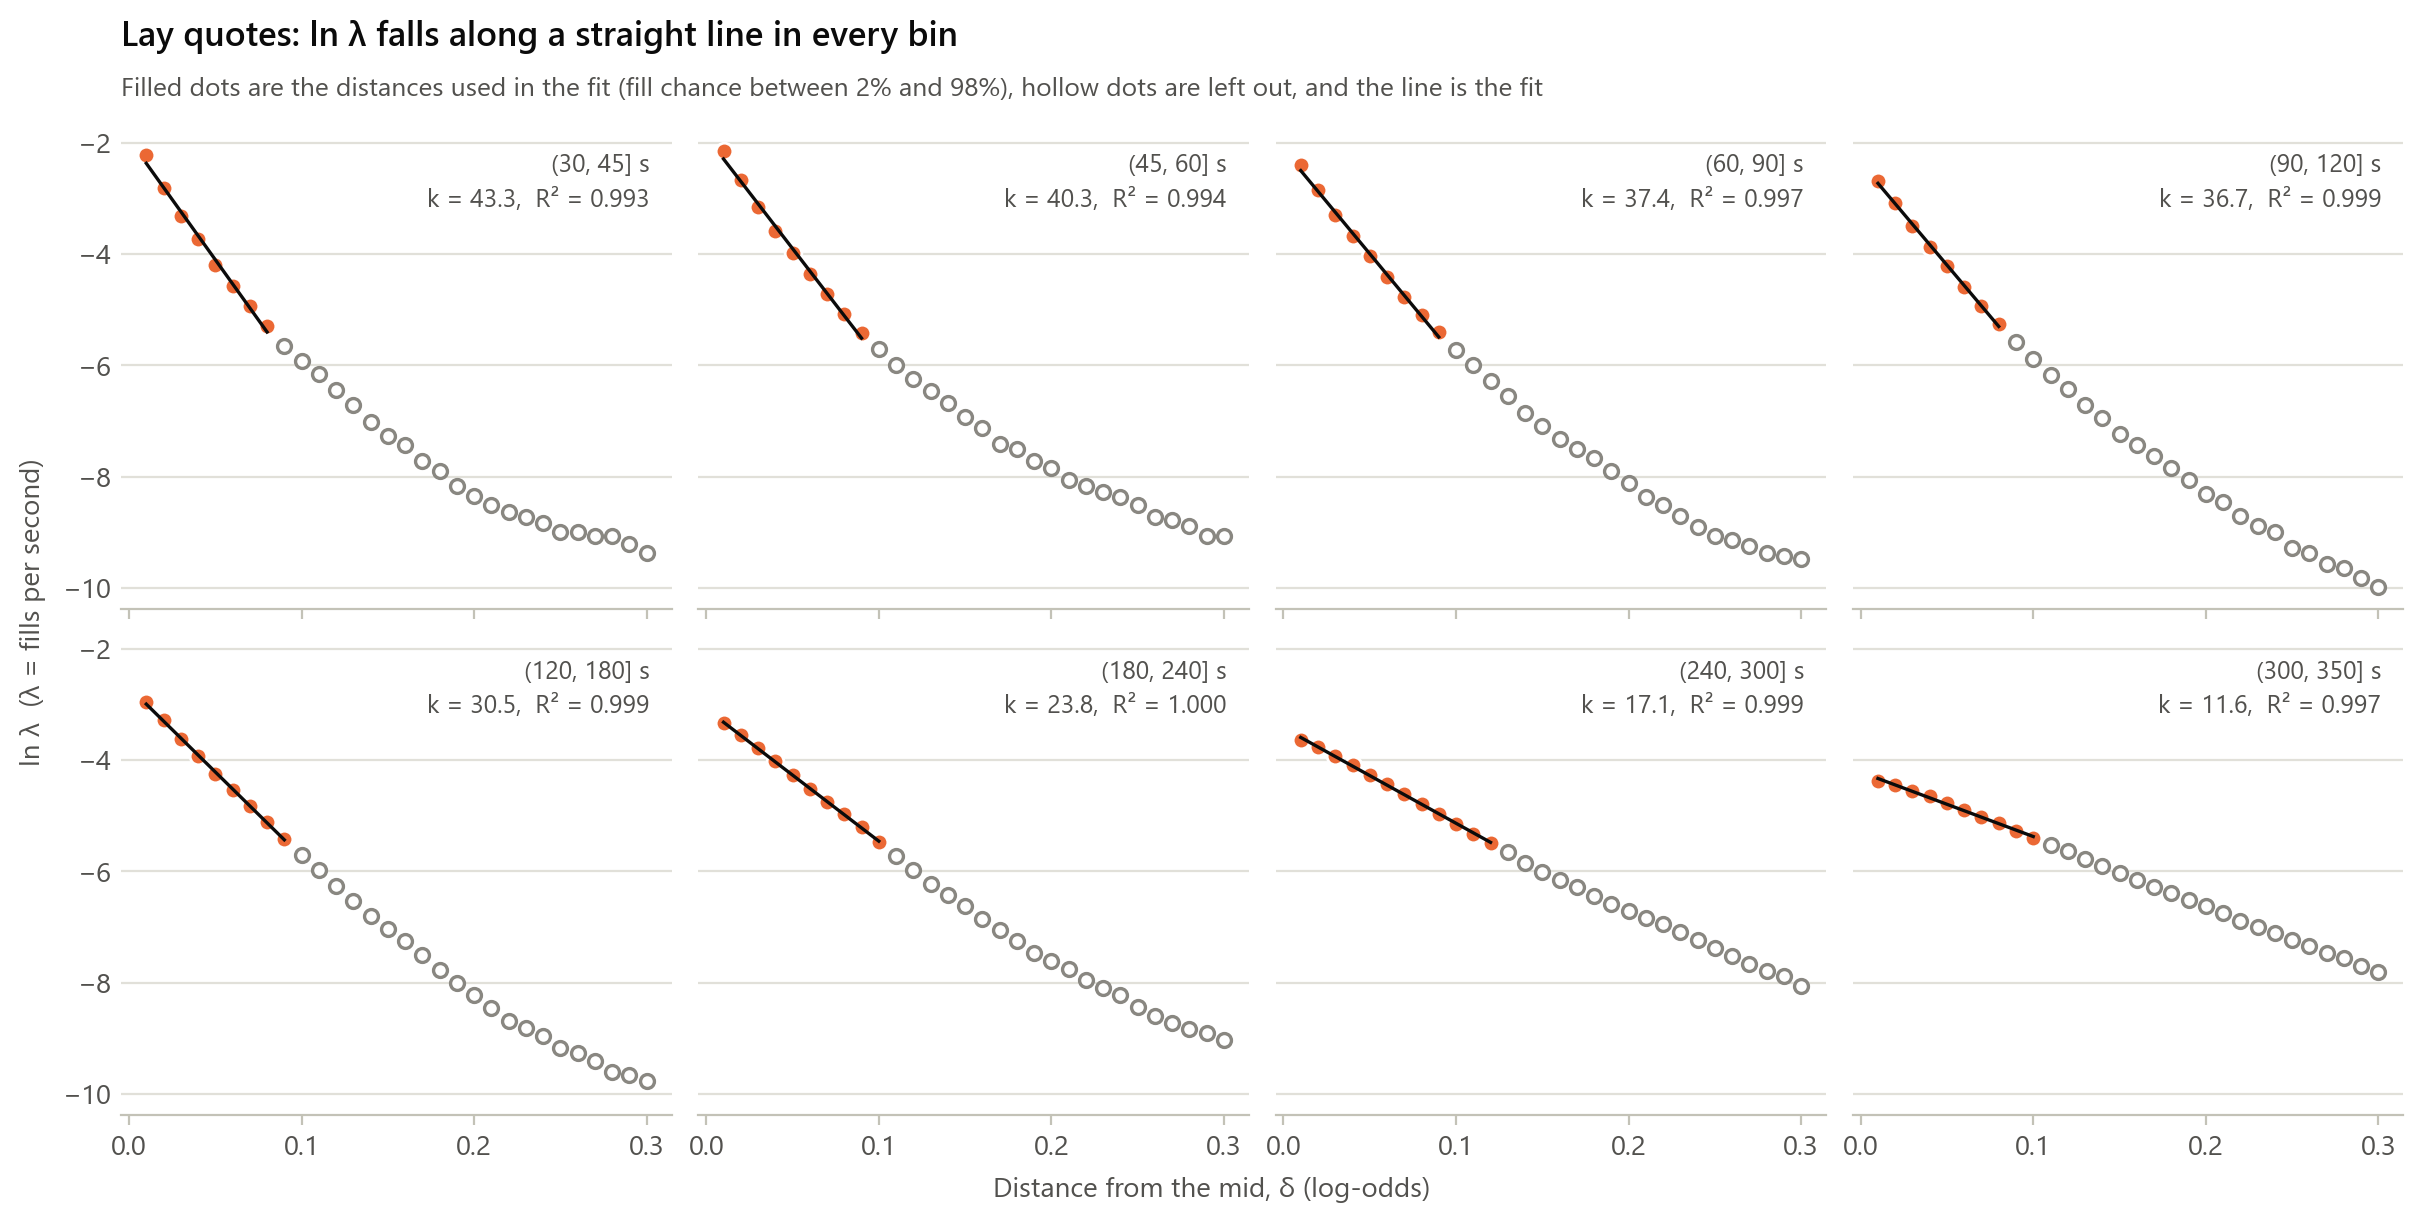

In [8]:
for side in SIDES:
    n_tot, h_tot = totals(EVERY_RACE, side)
    fig, axes = plt.subplots(2, 4, figsize=(12, 6), sharex=True, sharey=True, layout="constrained")
    for i, ax in enumerate(axes.flat):
        P, rate, usable = fill_rates(n_tot[i], h_tot[i])
        left_out = ~usable & (P > 0)                    # P = 0 can't be drawn: ln(0) = -inf
        ax.plot(DELTAS[left_out], np.log(rate[left_out]), "o", mfc="white", mec=GREY, mew=1.2, ms=5)
        ax.plot(DELTAS[usable], np.log(rate[usable]), "o", color=COLOURS[side], ms=6, mew=1)
        label = f"{LABELS[BINS[i]]} s"
        if usable.sum() >= 3:
            slope, intercept = np.polyfit(DELTAS[usable], np.log(rate[usable]), 1)
            r2 = np.corrcoef(DELTAS[usable], np.log(rate[usable]))[0, 1] ** 2
            ax.plot(DELTAS[usable], intercept + slope * DELTAS[usable], color=INK, lw=1.2)
            label += f"\nk = {-slope:.1f},  R² = {r2:.3f}"
        ax.text(0.96, 0.95, label, transform=ax.transAxes, ha="right", va="top", fontsize=9, color=INK_2,
                linespacing=1.5)
    fig.supxlabel("Distance from the mid, δ (log-odds)", color=INK_2, fontsize=10)
    fig.supylabel("ln λ  (λ = fills per second)", color=INK_2, fontsize=10)
    titles(axes[0, 0], f"{side.title()} quotes: ln λ falls along a straight line in every bin",
           "Filled dots are the distances used in the fit (fill chance between 2% and 98%), hollow dots are left out, "
           "and the line is the fit")
    plt.show()

The filled dots sit on a straight line in every bin, with R² of at least 0.99, so the exponential model fits the distances we use well. The hollow dots past the cut-off bend away from the line: very distant fills (a big price jump within 5 seconds) are more common than the exponential predicts. Those distances hold under 2% of windows and are well beyond where the strategy quotes, so leaving them out is what we want.

## Step 4: Problem bins

We ensure that all k values are sensible, but in our case when training on Janurary data, there are no problematic k values so this part is safe to ignore.

In [9]:
def merge_problem_bins(side):
    # Start with every bin on its own. While some group has k below MIN_K or can't be fitted, merge it with
    # its neighbouring group that has fewer windows, then refit. Returns the groups as lists of bin positions.
    groups = [[i] for i in range(len(BINS))]
    while len(groups) > 1:
        ks = k_by_group(EVERY_RACE, side, groups)
        problems = [i for i, k in enumerate(ks) if not k >= MIN_K]     # `not k >= 2` is also True for NaN
        if not problems:
            break
        i = problems[0]
        neighbours = [j for j in (i - 1, i + 1) if 0 <= j < len(groups)]
        j = min(neighbours, key=lambda j: window_counts[:, groups[j]].sum())
        lo, hi = sorted((i, j))
        groups[lo:hi + 1] = [groups[lo] + groups[hi]]
    return groups


def group_label(group):
    # e.g. [0] -> "(30, 45]", and [0, 1] -> "(30, 60]" if two bins were merged
    return f"({BIN_EDGES[group[0]]}, {BIN_EDGES[group[-1] + 1]}]"


groups = {side: merge_problem_bins(side) for side in SIDES}
for side in SIDES:
    merged = [group_label(g) for g in groups[side] if len(g) > 1]
    print(f"{side}: " + (f"merged into {', '.join(merged)}" if merged else f"no problem bins, all {len(BINS)} kept"))

back: no problem bins, all 8 kept
lay: no problem bins, all 8 kept


## Step 5: 95% confidence intervals (bootstrap by race)

As for σ², we resample **whole races**, not single windows. Runners in the same race are linked (when one shortens, others must drift), and a burst of news or a big punter hits the whole race at once. Treating every window as independent would make the intervals too narrow.

1. Draw $R$ races at random with replacement, where $R$ is the number of races.
2. Recompute $k$ from the drawn races, counting a race twice if it was drawn twice.
3. Repeat 1,000 times, sort the results, and take the 25th and 975th smallest values.

With the race totals from Step 2, a bootstrap sample is just a set of weights: how many times each race was drawn. `rng.multinomial` draws all 1,000 sets of weights at once. It's the same as picking $R$ races with replacement and counting how often each came up.

In [10]:
R = len(RACES)
draws = rng.multinomial(R, np.full(R, 1 / R), size=N_BOOT)   # draws[b, r] = times race r was picked in repeat b

boot = {side: np.array([k_by_group(weights, side, groups[side]) for weights in draws])   # repeats x bins
        for side in SIDES}
for side in SIDES:
    assert not np.isnan(boot[side]).any(), f"some {side} bootstrap samples couldn't be fitted"
ci = {side: np.sort(boot[side], axis=0)[[24, 974]] for side in SIDES}    # 25th and 975th smallest of 1,000

## Step 6: Is it stable from day to day?

We repeat the estimate using one day's races at a time. If $k$ jumped around a lot between days, a single month's average wouldn't be a reliable number to trade on. For each bin we record the median, minimum and maximum across the 31 days, and the **coefficient of variation** (CV = standard deviation ÷ mean). A CV of 0.2 means a typical day is about 20% away from the average.

Problem bins are only merged for the pooled estimate. A single day's bin has far fewer windows, so if it can't be fitted we leave it out of that day's numbers rather than merge.

In [11]:
race_day = windows.groupby("race")["day"].first().loc[RACES].to_numpy()    # the day of each race, in RACES order
DAYS = np.unique(race_day)
daily = {side: np.array([k_by_group((race_day == day).astype(float), side, groups[side]) for day in DAYS])
         for side in SIDES}                                                  # days x bins
for side in SIDES:
    print(f"{side}: {np.isnan(daily[side]).sum()} of {daily[side].size} day-and-bin estimates couldn't be fitted")

back: 2 of 248 day-and-bin estimates couldn't be fitted
lay: 0 of 248 day-and-bin estimates couldn't be fitted


## Spread check

One more check that the method makes sense: how wide is the market itself? For every book update in the window (350 s to 30 s, market open, mid odds 1.2–6.0) we measure the gap between the best back odds $B$ and the best lay odds $L$:

- in **ticks** on the price ladder;
- as a **half-spread** in log-odds, $\tfrac12\left[\ln(L-1) - \ln(B-1)\right]$, which is about how far each side of the book sits from the mid.

We report the median of each per bin. To keep memory low, each race reports how many updates showed each $(B, L)$ pair, and the medians are taken over those counts.

We compare the half-spread with $1/k$. A–S's half-spread is a volatility term plus a fill term, $\frac1\gamma\ln\left(1+\frac\gamma k\right)$. The fill term is never more than $1/k$, and is close to it when $\gamma$ is small next to $k$. So $1/k$ is a rough indication of how far from the mid A–S would quote, before the volatility and inventory terms are added.

In [12]:
def spreads_in_race(path):
    # How many book updates in the window showed each (best back, best lay) pair, per time bin
    book = load_book(path)
    counted = (book["status"] == "OPEN") & book["ttj"].between(30, 350) & book["odds"].between(MIN_ODDS, MAX_ODDS)
    book = book[counted]
    time_bin = pd.cut(book["ttj"], BIN_EDGES, labels=BINS).rename("bin")
    return book.groupby([time_bin, "back_price_1", "lay_price_1"], observed=True).size()


spreads = pd.concat(Parallel(n_jobs=-1)(delayed(spreads_in_race)(f) for f in FILES))
spreads = spreads.groupby(level=[0, 1, 2]).sum().rename("updates").reset_index()
B, L = spreads["back_price_1"], spreads["lay_price_1"]


def ladder_position(price):
    # Where each price sits on the ladder (1.01 is 0, 1.02 is 1, ...), so a difference counts ticks
    return np.searchsorted(LADDER, price - 1e-9)


spreads["ticks"] = ladder_position(L) - ladder_position(B)
spreads["half_spread"] = 0.5 * (np.log(L - 1) - np.log(B - 1))


def weighted_median(values, weights):
    # The value with half of the total weight at or below it
    order = np.argsort(values)
    cumulative = np.cumsum(weights[order])
    return values[order][np.searchsorted(cumulative, cumulative[-1] / 2)]


by_bin = spreads.groupby("bin", observed=True)
spread_check = pd.DataFrame({
    "book updates": by_bin["updates"].sum(),
    "median spread (ticks)": by_bin.apply(lambda g: weighted_median(g["ticks"].to_numpy(), g["updates"].to_numpy())),
    "median half-spread": by_bin.apply(lambda g: weighted_median(g["half_spread"].to_numpy(), g["updates"].to_numpy())),
    "1/k back": 1 / k_per_bin["back"],
    "1/k lay": 1 / k_per_bin["lay"],
})
spread_check.index = [LABELS[b] for b in spread_check.index]
spread_check.index.name = "seconds before off"
spread_check.round(3)

,book updates,median spread (ticks),median half-spread,1/k back,1/k lay
seconds before off,,,,,
"(30, 45]",1136956,2,0.017,0.021,0.023
"(45, 60]",1167534,2,0.020,0.026,0.025
"(60, 90]",2131424,2,0.023,0.026,0.027
"(90, 120]",1996432,3,0.026,0.027,0.027
"(120, 180]",3797994,3,0.033,0.030,0.033
"(180, 240]",3747678,5,0.053,0.037,0.042
"(240, 300]",3652555,9,0.088,0.050,0.058
"(300, 350]",1516586,13,0.124,0.069,0.086


**What the spread check tells us.**

- **The distances we fit are the ones that matter.** The fit uses δ from 0.01 out to about 0.06–0.12 (where P drops below 2%). Near the off, the median half-spread is about 0.02, so that range runs from the best prices out to several ticks behind them. Far from the off the book is much wider (13 ticks across, a half-spread of about 0.12), so the fitted distances are mostly *inside* the spread, where our quote would be the new best price. Our quote there would be the best price on offer, first in line, and the fill rules in Step 1 treat it that way.
- **The k values give sensible quotes.** $1/k$ is close to the market's own half-spread in the last two minutes. Further from the off it's well inside it, so A–S would quote inside a wide, thin book, ahead of everyone else. Both follow the same pattern: wide early and tight near the off.

## Results

All $k$ values are in log-odds units (per unit of log-odds distance).

In [13]:
def summary(side):
    gs = groups[side]
    d = daily[side]
    return pd.DataFrame({
        "windows": [window_counts[:, g].sum() for g in gs],
        "k": k_by_group(EVERY_RACE, side, gs),
        "95% CI low": ci[side][0],
        "95% CI high": ci[side][1],
        "daily median": np.nanmedian(d, axis=0),
        "daily min": np.nanmin(d, axis=0),
        "daily max": np.nanmax(d, axis=0),
        "daily CV": np.nanstd(d, axis=0, ddof=1) / np.nanmean(d, axis=0),
    }, index=[group_label(g) for g in gs])


results = pd.concat({side: summary(side) for side in SIDES}, names=["side", "seconds before off"])
results.round(2)

windows      k  95% CI low  95% CI high  \
side seconds before off                                            
back (30, 45]              25996  47.41       44.59        48.77   
     (45, 60]              26019  38.06       36.94        39.14   
     (60, 90]              52084  38.73       37.84        39.64   
     (90, 120]             52059  36.58       35.42        37.53   
     (120, 180]           104127  32.93       32.15        33.64   
     (180, 240]           102299  27.23       26.52        27.96   
     (240, 300]            99077  20.01       19.32        20.73   
     (300, 350]            79984  14.43       13.47        15.27   
lay  (30, 45]              25996  43.30       42.15        44.44   
     (45, 60]              26019  40.25       39.24        41.41   
     (60, 90]              52084  37.38       36.53        38.19   
     (90, 120]             52059  36.74       35.43        37.59   
     (120, 180]           104127  30.48       29.84        31.14   
     (180, 240]           102299  23.75       23.16        24.26   
     (240, 300]            99077  17.14       16.62        17.64   
     (300, 350]            79984  11.59       11.13        12.20   

                         daily median  daily min  daily max  daily CV  
side seconds before off                                                
back (30, 45]                   47.16      33.62      60.39      0.13  
     (45, 60]                   38.17      31.38      46.52      0.11  
     (60, 90]                   38.21      34.35      46.86      0.09  
     (90, 120]                  36.84      31.00      47.67      0.11  
     (120, 180]                 33.33      26.31      37.68      0.08  
     (180, 240]                 26.79      20.84      33.11      0.10  
     (240, 300]                 19.48      15.14      26.91      0.14  
     (300, 350]                 14.01       7.32      22.41      0.24  
lay  (30, 45]                   43.38      26.83      54.65      0.13  
     (45, 60]                   39.79      30.41      48.69      0.11  
     (60, 90]                   38.12      30.84      49.14      0.11  
     (90, 120]                  37.22      28.29      45.53      0.10  
     (120, 180]                 31.29      24.73      36.83      0.10  
     (180, 240]                 24.01      17.58      30.45      0.12  
     (240, 300]                 17.52      11.96      21.28      0.15  
     (300, 350]                 11.70       7.06      18.97      0.20

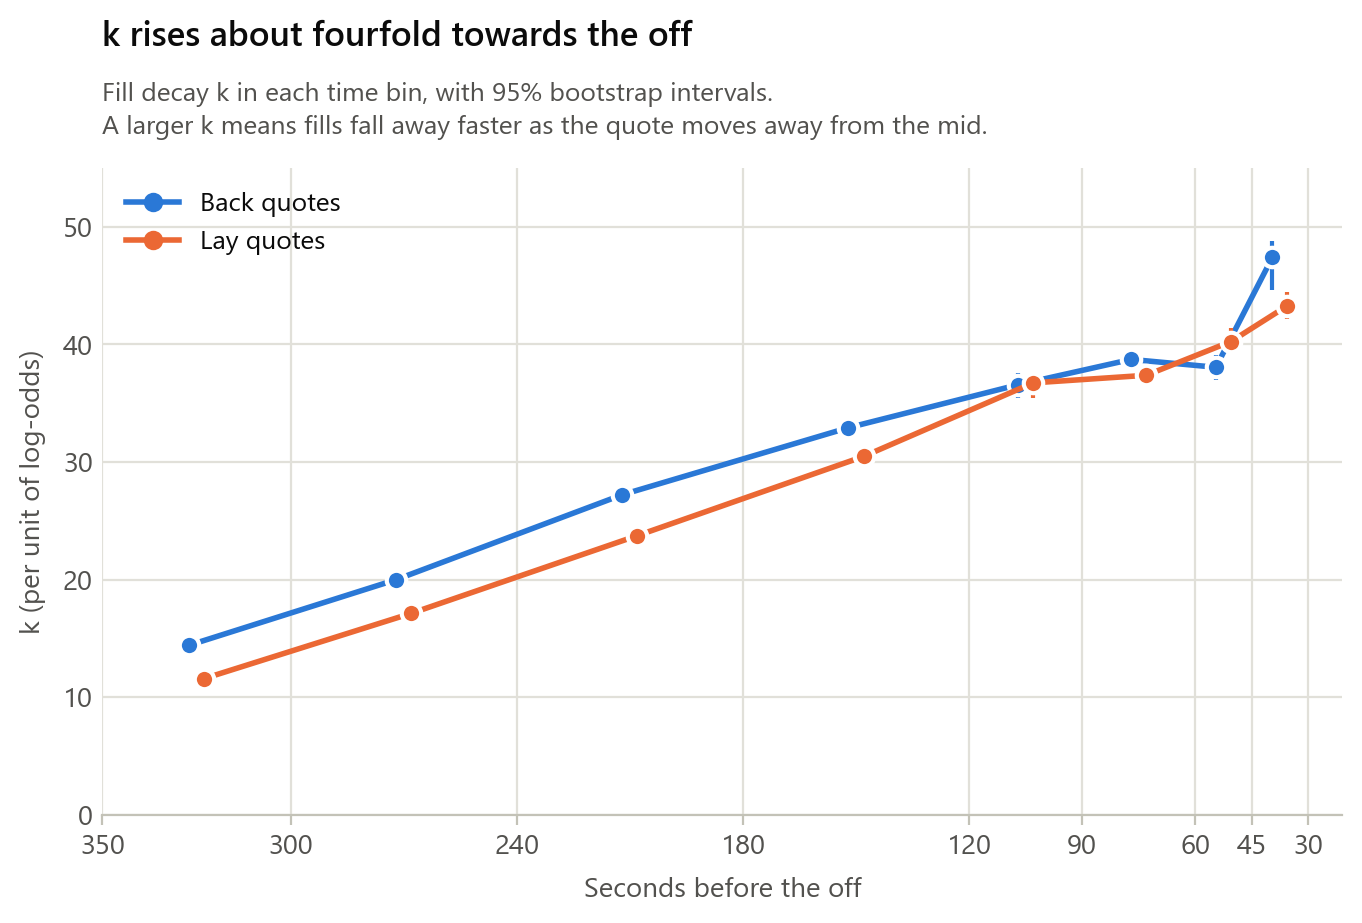

In [14]:
def middles(side):
    # Middle of each group of bins, in seconds before the off (for plotting)
    return np.array([(BIN_EDGES[g[0]] + BIN_EDGES[g[-1] + 1]) / 2 for g in groups[side]])


def bin_axis(ax, ticks=BIN_EDGES):
    # Time runs left to right towards the off, with a vertical hairline at every tick
    ax.invert_xaxis()
    ax.set_xticks(ticks)
    ax.grid(True, axis="x")
    ax.set_xlabel("Seconds before the off")


fig, ax = plt.subplots()
for side, nudge in [("back", 2), ("lay", -2)]:      # nudge the two sides apart so their bars don't overlap
    k = results.loc[side, "k"].to_numpy()
    ax.errorbar(middles(side) + nudge, k, yerr=[k - ci[side][0], ci[side][1] - k], fmt="none",
                ecolor=COLOURS[side], elinewidth=1.5)
    ax.plot(middles(side) + nudge, k, "-o", color=COLOURS[side], label=f"{side.title()} quotes")
bin_axis(ax)
ax.set(ylabel="k (per unit of log-odds)", ylim=(0, 55))
legend(ax, loc="upper left")
titles(ax, "k rises about fourfold towards the off",
       "Fill decay k in each time bin, with 95% bootstrap intervals.\n"
       "A larger k means fills fall away faster as the quote moves away from the mid.")
plt.show()

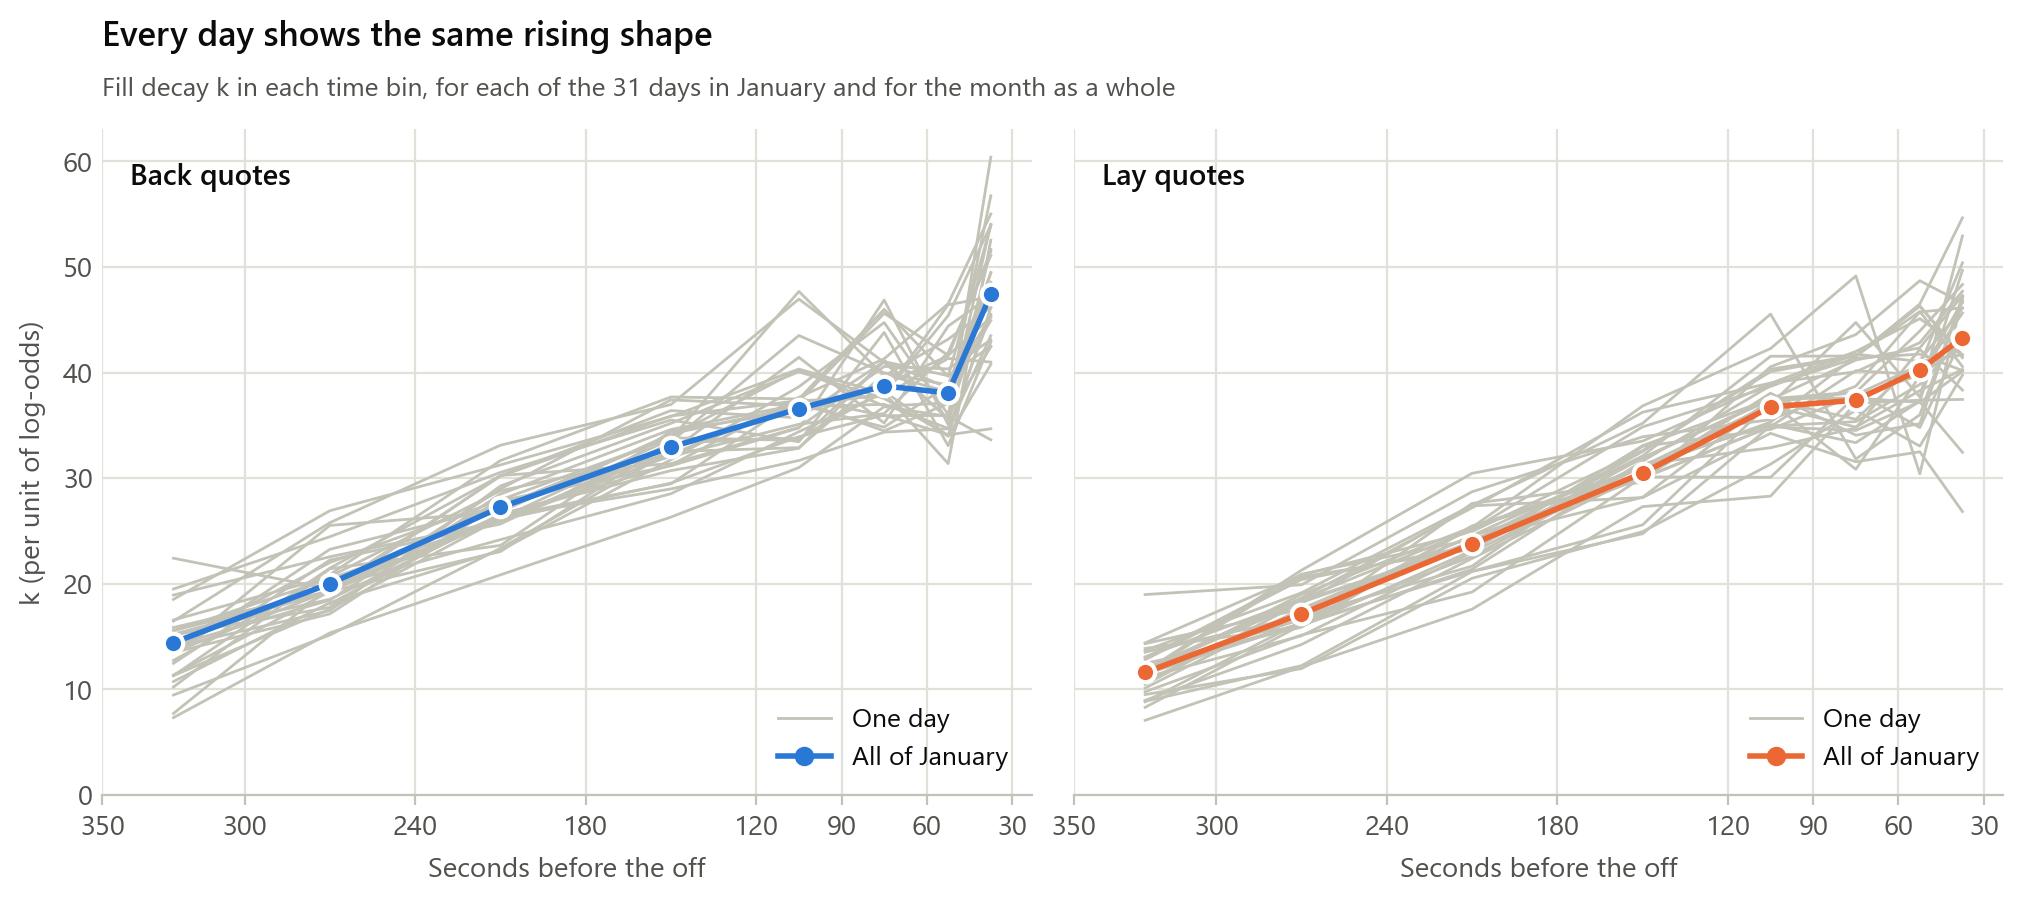

In [15]:
fig, axes = plt.subplots(1, 2, sharey=True, figsize=(10, 4.4), layout="constrained")
for ax, side in zip(axes, SIDES):
    day_lines = ax.plot(middles(side), daily[side].T, color=LIGHT, lw=1)    # one line per day
    day_lines[0].set_label("One day")
    ax.plot(middles(side), results.loc[side, "k"], "-o", color=COLOURS[side], label="All of January")
    bin_axis(ax, ticks=[30, 60, 90, 120, 180, 240, 300, 350])   # no room for 45 in a narrow panel
    ax.text(0.03, 0.95, f"{side.title()} quotes", transform=ax.transAxes, va="top", fontsize=10.5,
            fontweight="semibold")
    legend(ax, loc="lower right")
axes[0].set(ylabel="k (per unit of log-odds)", ylim=(0, None))
titles(axes[0], "Every day shows the same rising shape",
       "Fill decay k in each time bin, for each of the 31 days in January and for the month as a whole")
plt.show()

### Back against lay: is the gap real?

We estimate a separate $k$ for each side, so it's worth checking that the two really differ. Every bootstrap repeat in Step 5 draws the same races for both sides, so the difference $k_{\text{back}} - k_{\text{lay}}$ in each repeat gives a **paired** 95% interval for the gap. That's a sharper test than checking whether the two sides' own intervals overlap, because it cancels out whatever the two sides have in common (a busy day, a lively race).

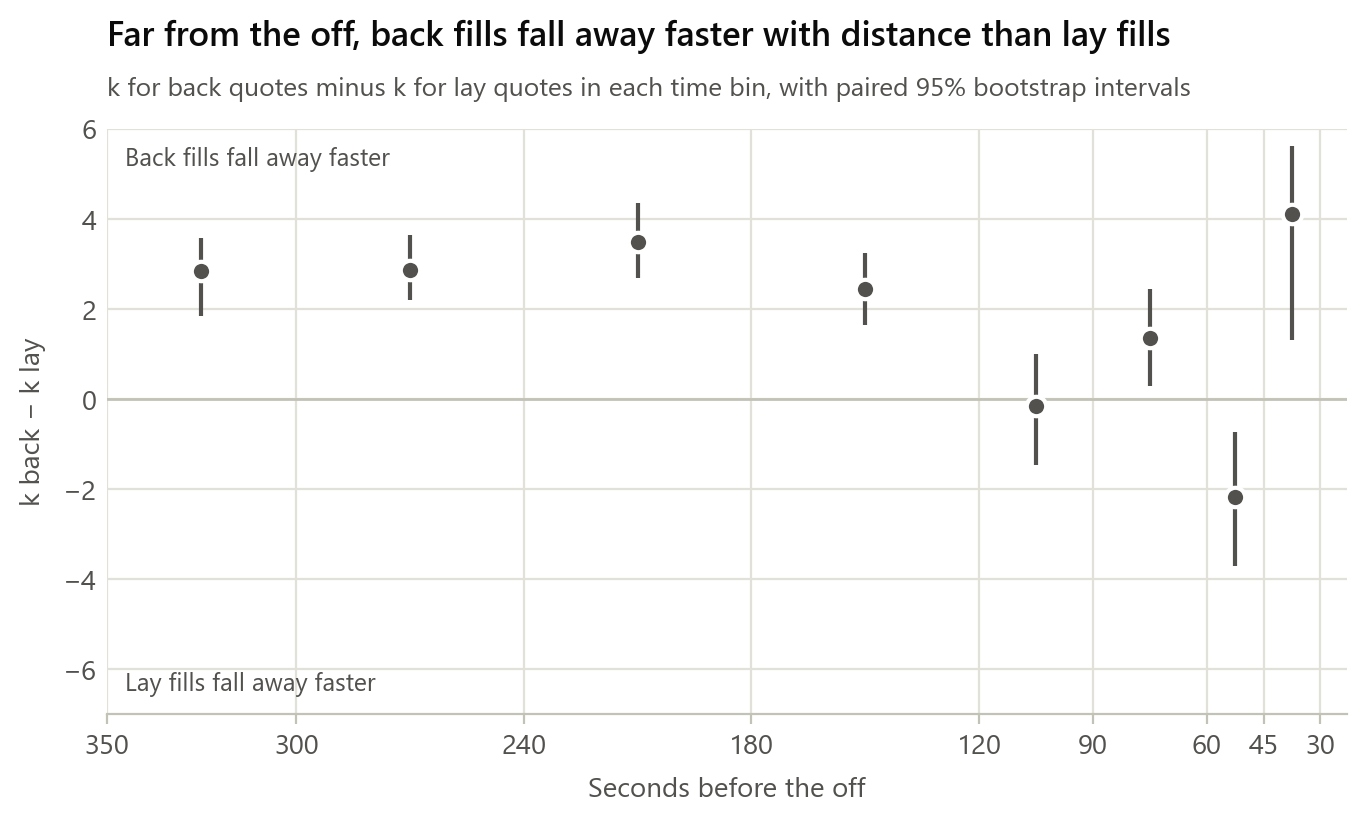

,k back,k lay,back − lay,95% CI low,95% CI high,"fill at δ = 0.01, back","fill at δ = 0.01, lay"
"(30, 45]",47.414,43.304,4.111,1.305,5.617,0.378,0.419
"(45, 60]",38.062,40.252,-2.190,-3.721,-0.729,0.380,0.442
"(60, 90]",38.729,37.381,1.349,0.290,2.430,0.288,0.364
"(90, 120]",36.577,36.736,-0.160,-1.475,0.987,0.226,0.290
"(120, 180]",32.927,30.482,2.446,1.629,3.228,0.174,0.227
"(180, 240]",27.228,23.750,3.477,2.674,4.341,0.122,0.163
"(240, 300]",20.007,17.143,2.865,2.195,3.634,0.087,0.124
"(300, 350]",14.425,11.592,2.833,1.829,3.574,0.041,0.061


In [16]:
assert groups["back"] == groups["lay"]                   # no bins were merged, so the sides line up bin by bin
gap = np.sort(boot["back"] - boot["lay"], axis=0)        # same races in every repeat: a paired comparison

back_vs_lay = pd.DataFrame({"k back": results.loc["back", "k"].to_numpy(),
                            "k lay": results.loc["lay", "k"].to_numpy()},
                           index=[group_label(g) for g in groups["back"]])
back_vs_lay["back − lay"] = back_vs_lay["k back"] - back_vs_lay["k lay"]
back_vs_lay["95% CI low"], back_vs_lay["95% CI high"] = gap[24], gap[974]
for side in SIDES:                                       # chance a quote 0.01 from the mid is filled within 5 s
    n_tot, h_tot = totals(EVERY_RACE, side)
    back_vs_lay[f"fill at δ = 0.01, {side}"] = h_tot[:, 0] / n_tot

fig, ax = plt.subplots(figsize=(8, 3.8))
difference = back_vs_lay["back − lay"].to_numpy()
ax.axhline(0, color=LIGHT, lw=1)
ax.errorbar(middles("back"), difference, yerr=[difference - gap[24], gap[974] - difference], fmt="none",
            ecolor=INK_2, elinewidth=1.5)
ax.plot(middles("back"), difference, "o", color=INK_2)
bin_axis(ax)
ax.set(ylabel="k back − k lay", ylim=(-7, 6))
ax.text(345, 5.6, "Back fills fall away faster", color=INK_2, fontsize=9, va="top")
ax.text(345, -6.6, "Lay fills fall away faster", color=INK_2, fontsize=9, va="bottom")
titles(ax, "Far from the off, back fills fall away faster with distance than lay fills",
       "k for back quotes minus k for lay quotes in each time bin, with paired 95% bootstrap intervals")
plt.show()
back_vs_lay.round(3)

**What this shows**

- **From 120 s out, the gap is real.** Back quotes have a larger $k$ than lay quotes in every bin from 120 to 350 s before the off, by 2.4–3.5 (8–24%), and every paired interval is clear of zero.
- **In the last two minutes there's no consistent gap.** The sign flips from bin to bin (lays are higher at 45–60 s, backs at 30–45 s), so we don't read anything into the direction there.
- **Lay quotes are also filled more often.** A lay 0.01 above the mid is filled 10–50% more often than a back 0.01 below it, in every bin.

**Why would the sides differ?** A lay quote is filled by someone backing, and a back quote by someone laying. Both findings point the same way: backers arrive more often and, far from the off, when the book is thin and wide, their trades reach further from the mid. A likely reason is that much of the money in these markets comes from punters backing a dog at whatever price is on offer, while layers tend to be choosier about price. Close to the off the book is deep and only about 2 ticks wide, so both kinds of trade happen near the mid and the two sides look alike.

**What it means for the strategy.** A smaller $k$ makes the A–S fill term $\frac1\gamma\ln\left(1+\frac\gamma k\right)$ bigger, so far from the off the strategy quotes its lay slightly further from the mid than its back. Using $1/k$ as a yardstick, the gap is about 0.005–0.017 in log-odds from 180 s out, about a tick at most. It's small, but the data pins it down precisely, so we keep the two sides separate.

## Table for the strategy

The strategy (`strategies/_final-strategy.py`) reads each $k$ table as a list of `(upper edge in seconds, value)` and interpolates linearly between the bin middles. The last edge becomes `INF`, so the final value also covers anything further from the off. If any bins were merged in Step 4, the merged bin appears once, under its upper edge.

In [17]:
for side in SIDES:
    edges = [str(BIN_EDGES[g[-1] + 1]) for g in groups[side][:-1]] + ["INF"]
    values = results.loc[side, "k"]
    print(f"K_{side.upper()}_X = [" + ", ".join(f"({e}, {v:.1f})" for e, v in zip(edges, values)) + "]")

K_BACK_X = [(45, 47.4), (60, 38.1), (90, 38.7), (120, 36.6), (180, 32.9), (240, 27.2), (300, 20.0), (INF, 14.4)]
K_LAY_X = [(45, 43.3), (60, 40.3), (90, 37.4), (120, 36.7), (180, 30.5), (240, 23.8), (300, 17.1), (INF, 11.6)]


## Reading the results

- **Shape.** $k$ rises steadily towards the off, from about 12–14 at 300–350 s to about 43–47 at 30–45 s, roughly three to four times larger. Close to the off, fills fall away with distance much faster.
- **In plain terms.** One tick is about 0.02 in log-odds. Moving a quote one tick further from the mid multiplies its fill rate by $e^{-0.02k}$. At $k = 14$ the quote keeps 76% of its fills, but at $k = 47$ it keeps only 39%. Early on, stepping back costs little. In the last minute, every tick costs more than half the fills.
- **Back vs lay.** From 120 s out, the lay's $k$ is 7–20% smaller than the back's, and the paired bootstrap puts every one of those gaps clear of zero. In the last two minutes there's no consistent direction. Lays are also filled 10–50% more often near the mid. Backers arrive more often and, early on, trade further from the mid, so the strategy can quote its lay a little wider. Keeping the sides separate is worth it.
- **Precision.** With almost 4,000 races, every 95% interval is within about 7% of its estimate.
- **Day to day.** In most bins a typical day is within 8–15% of the January value (daily CV 0.08–0.15), so $k$ is steadier than σ² (CV 0.20–0.35). The exception is the earliest bin, 300–350 s (CV 0.24 for backs, 0.20 for lays), where trading is thinnest. Every day shows the same rising shape.
- **Fit.** The exponential shape fits well, with R² of at least 0.993 in every bin.
- **Queue position.** Fills follow the backtest engine's rules, queue included, so a quote that joins a busy price waits its turn here just as it will in the backtest. What nobody can see is where in the queue cancellations happen. Like the engine, we assume the people ahead of us cancel first, which is slightly optimistic, so our values near the off may still be a little high.